# 🎯 Real-Time Object Detection — Exploratory Data Analysis

**Dataset:** COCO (Common Objects in Context) — 2017 split, auto-downloaded in this notebook
**Task:** Multi-class, multi-object detection with bounding boxes (YOLO-style real-time detector)
**Author:** Senior Data Science Team

---

## 📦 Business Problem
Reliance Retail, Amazon warehouses, Bosch manufacturing lines, and surveillance/security vendors all rely on **YOLO-family real-time object detectors** for:
- **Shelf monitoring** — detecting empty shelves, misplaced products, stock-outs
- **Defect / safety detection** — spotting missing PPE, damaged parts, foreign objects on a line
- **Intrusion & perimeter alerts** — detecting people, vehicles, bags in restricted zones, in real time, from CCTV feeds

Unlike tabular risk/fraud problems, the "rows" here are **images** and the "target" is a **variable-length set of (class, bounding box) pairs per image**. This changes almost every EDA question: instead of feature distributions we care about *object scale, aspect ratio, spatial position, class co-occurrence, and image quality* — because these directly drive **anchor box design, input resolution, augmentation strategy, and loss weighting** for the detector.

**Goal:** Profile the COCO dataset the way a senior CV engineer would before configuring a YOLO training pipeline — so every architecture and augmentation decision is backed by evidence, not defaults.

## 📌 Notebook Workflow
| Step | Topic |
|------|-------|
| 1 | Import libraries |
| 2 | Auto-download COCO dataset (images + annotations) |
| 3 | Parse annotations into structured DataFrames |
| 4 | Dataset structure and schema |
| 5 | Data integrity checks (corrupt / degenerate annotations) |
| 6 | Duplicate image detection |
| 7 | Image resolution statistical summary |
| 8 | Class distribution and imbalance analysis |
| 9 | Objects-per-image distribution |
| 10 | Bounding box size distribution (small / medium / large) |
| 11 | Bounding box aspect ratio distribution |
| 12 | Image aspect ratio analysis (resize / letterbox strategy) |
| 13 | Spatial distribution of object centers (center-bias) |
| 14 | Class co-occurrence analysis |
| 15 | Sample visualizations with bounding boxes |
| 16 | Small-object detection challenge |
| 17 | Anchor box design via K-Means clustering |
| 18 | Image brightness / low-light analysis |
| 19 | Annotation schema note — crowd/occlusion handling |
| 20 | Train / validation split strategy for detection |
| 21 | Key insights and pipeline design summary |

---
## Step 1 — Import Libraries
**Why:** All required libraries imported upfront. `PIL` reads image pixels/metadata directly (no need for a heavier CV framework at EDA stage). `sklearn.cluster.KMeans` powers anchor-box design in Step 17 — the same technique used in the original YOLOv2 paper.

In [1]:
import os, glob, hashlib, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
})
BLUE = '#2196F3'; PINK = '#E91E63'; GRAY = '#90A4AE'; GREEN = '#4CAF50'; ORANGE = '#FF9800'
print('✅ Libraries loaded successfully')

C:\Users\Narendra Kalam\AppData\Roaming\Python\Python39\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


✅ Libraries loaded successfully


---
## Step 2 — Auto-Download COCO Dataset (Images + Annotations)
**Why:** The dataset was not provided locally, so the notebook must fetch it itself and be fully reproducible on a fresh machine — no manual download step for the next engineer who runs this notebook.

**Dataset choice:** Full COCO2017 (`train2017` + `val2017`) is ~25 GB of images plus a ~240 MB annotation archive — expensive to pull just for EDA, and unnecessary to profile class balance, box geometry, and image statistics. We auto-download **`coco128`**, Ultralytics' official 128-image subset of COCO2017 `train2017`, distributed with **real COCO images and real COCO annotations** (converted to YOLO's normalized `[class, x_center, y_center, w, h]` format). This is the same subset used to smoke-test every major YOLO release before a full training run.

**Business context:** The auto-download pattern below is production-safe — it checks for a local cache first, downloads only if missing, and verifies the extraction. The same `download_and_extract()` function is reused with the full `train2017.zip` / `val2017.zip` URLs once the pipeline moves from EDA to full-scale training (see the commented block).

In [2]:
DATA_DIR = './data'
os.makedirs(DATA_DIR, exist_ok=True)

COCO128_URL = 'https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip'
ZIP_PATH = os.path.join(DATA_DIR, 'coco128.zip')
EXTRACT_DIR = os.path.join(DATA_DIR, 'coco128')

def download_and_extract(url, zip_path, extract_dir):
    if os.path.isdir(extract_dir):
        print(f'✅ Already downloaded — using cached copy at {extract_dir}')
        return
    print(f'⬇️  Downloading {url} ...')
    urllib.request.urlretrieve(url, zip_path)
    size_mb = os.path.getsize(zip_path) / (1024 ** 2)
    print(f'   Downloaded {size_mb:.1f} MB')
    print('📦 Extracting ...')
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
    os.remove(zip_path)
    print(f'✅ Extracted to {extract_dir}')

download_and_extract(COCO128_URL, ZIP_PATH, EXTRACT_DIR)

IMG_DIR = os.path.join(EXTRACT_DIR, 'images', 'train2017')
LBL_DIR = os.path.join(EXTRACT_DIR, 'labels', 'train2017')
n_images = len(glob.glob(os.path.join(IMG_DIR, '*.jpg')))
n_labels = len(glob.glob(os.path.join(LBL_DIR, '*.txt')))
print(f'\nImages found : {n_images}')
print(f'Labels found : {n_labels}')

# ── Full-scale production path (commented — run when moving beyond EDA) ──
# FULL_URLS = {
#     'train_images': 'http://images.cocodataset.org/zips/train2017.zip',       # ~19 GB
#     'val_images':   'http://images.cocodataset.org/zips/val2017.zip',          # ~1 GB
#     'annotations':  'http://images.cocodataset.org/annotations/annotations_trainval2017.zip',  # ~241 MB
# }
# for name, url in FULL_URLS.items():
#     download_and_extract(url, os.path.join(DATA_DIR, f'{name}.zip'), os.path.join(DATA_DIR, name))

# The 80 official COCO object categories (fixed order — index = YOLO class_id)
COCO_CLASSES = ['person','bicycle','car','motorcycle','airplane','bus','train','truck','boat',
'traffic light','fire hydrant','stop sign','parking meter','bench','bird','cat','dog','horse',
'sheep','cow','elephant','bear','zebra','giraffe','backpack','umbrella','handbag','tie','suitcase',
'frisbee','skis','snowboard','sports ball','kite','baseball bat','baseball glove','skateboard',
'surfboard','tennis racket','bottle','wine glass','cup','fork','knife','spoon','bowl','banana',
'apple','sandwich','orange','broccoli','carrot','hot dog','pizza','donut','cake','chair','couch',
'potted plant','bed','dining table','toilet','tv','laptop','mouse','remote','keyboard','cell phone',
'microwave','oven','toaster','sink','refrigerator','book','clock','vase','scissors','teddy bear',
'hair drier','toothbrush']
print(f'COCO category count: {len(COCO_CLASSES)}')

⬇️  Downloading https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip ...
   Downloaded 6.7 MB
📦 Extracting ...
✅ Extracted to ./data\coco128

Images found : 128
Labels found : 128
COCO category count: 80


**📌 Observation:** The auto-download completed successfully — 128 real COCO images with matching YOLO-format label files, drawn from the 80 official COCO categories.

**💡 Pipeline decision:** `download_and_extract()` is idempotent (checks cache before re-downloading) so it is safe to call on every pipeline run, including in CI. The same function scales to the full `train2017`/`val2017` archives by swapping the URL — no other code changes needed downstream.

---
## Step 3 — Parse Annotations into Structured DataFrames
**Why:** Detection labels are one-to-many (one image → many boxes), so a single tabular `df` (like in credit-risk/fraud EDA) isn't enough. We build **two** DataFrames — `img_df` (one row per image) and `ann_df` (one row per bounding box) — mirroring how COCO's own `images` and `annotations` tables are structured internally.

**Business insight:** This image/annotation split is exactly what the training `Dataset` class will consume later — building it explicitly at EDA time catches format issues (bad normalization, out-of-range classes) before they silently corrupt model training.

In [3]:
def parse_coco128(img_dir, lbl_dir, class_names):
    img_rows, ann_rows = [], []
    for img_path in sorted(glob.glob(os.path.join(img_dir, '*.jpg'))):
        fname = os.path.basename(img_path)
        stem = os.path.splitext(fname)[0]
        lbl_path = os.path.join(lbl_dir, stem + '.txt')

        with Image.open(img_path) as im:
            w, h = im.size
            mode = im.mode

        n_obj = 0
        if os.path.exists(lbl_path):
            for line in open(lbl_path):
                parts = line.split()
                if len(parts) < 5:
                    continue
                cls, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:5])
                px_w, px_h = bw * w, bh * h
                x1, y1 = (xc - bw / 2) * w, (yc - bh / 2) * h
                x2, y2 = (xc + bw / 2) * w, (yc + bh / 2) * h
                ann_rows.append(dict(
                    image=fname, img_w=w, img_h=h,
                    class_id=cls, class_name=class_names[cls],
                    xc_norm=xc, yc_norm=yc, bw_norm=bw, bh_norm=bh,
                    x1=x1, y1=y1, x2=x2, y2=y2,
                    px_w=px_w, px_h=px_h, area_px=px_w * px_h,
                    aspect_ratio=round(px_w / px_h, 3) if px_h > 0 else np.nan))
                n_obj += 1
        img_rows.append(dict(image=fname, img_w=w, img_h=h, mode=mode, n_objects=n_obj))
    return pd.DataFrame(img_rows), pd.DataFrame(ann_rows)

img_df, ann_df = parse_coco128(IMG_DIR, LBL_DIR, COCO_CLASSES)
print(f'img_df : {img_df.shape}  (1 row per image)')
print(f'ann_df : {ann_df.shape}  (1 row per bounding box)')
ann_df.head()

img_df : (128, 5)  (1 row per image)
ann_df : (929, 17)  (1 row per bounding box)


,image,img_w,img_h,class_id,class_name,xc_norm,yc_norm,bw_norm,bh_norm,x1,y1,x2,y2,px_w,px_h,area_px,aspect_ratio
0,000000000009.jpg,640,480,45,bowl,0.479492,0.688771,0.955609,0.595500,1.08000,187.69008,612.66976,473.53008,611.58976,285.84000,174816.816998,2.140
1,000000000009.jpg,640,480,45,bowl,0.736516,0.247188,0.498875,0.476417,311.73024,4.31016,631.01024,232.99032,319.28000,228.68016,73013.001485,1.396
2,000000000009.jpg,640,480,50,broccoli,0.637063,0.732938,0.494125,0.510583,249.60032,229.27032,565.84032,474.35016,316.24000,245.07984,77504.048602,1.290
3,000000000009.jpg,640,480,45,bowl,0.339438,0.418896,0.678875,0.781500,0.00032,13.51008,434.48032,388.63008,434.48000,375.12000,162982.137600,1.158
4,000000000009.jpg,640,480,49,orange,0.646836,0.132552,0.118047,0.096937,376.20000,40.35996,451.75008,86.88996,75.55008,46.53000,3515.345222,1.624


**📌 Observation:** 128 images produce roughly 900+ bounding boxes — an average well above 1 object per image, confirming this is a genuine multi-object detection problem, not single-label classification.

**💡 Pipeline decision:** `parse_coco128()` becomes the reusable ingestion function inside the training `Dataset.__getitem__` — same normalization math, so anything validated here in EDA is guaranteed consistent with what the model will actually see.

---
## Step 4 — Dataset Structure and Schema
**Why:** Before any statistics, confirm dtypes and value ranges are sane — normalized coordinates must fall in `[0, 1]`, pixel coordinates must fall inside image bounds, and `class_id` must be a valid COCO index. Catching a schema bug here is far cheaper than debugging a `CUDA out of bounds` error mid-training.

In [4]:
schema_df = pd.DataFrame({
    'dtype': ann_df.dtypes,
    'non_null': ann_df.notna().sum(),
    'min': ann_df.select_dtypes(include=np.number).min(),
    'max': ann_df.select_dtypes(include=np.number).max(),
})
print('Annotation-level schema:')
display(schema_df)

print(f"\nTotal images          : {len(img_df):,}")
print(f"Total annotations      : {len(ann_df):,}")
print(f"Unique classes present : {ann_df['class_name'].nunique()} / {len(COCO_CLASSES)} COCO categories")
coord_cols = ann_df[['xc_norm', 'yc_norm', 'bw_norm', 'bh_norm']]
coords_valid = coord_cols.apply(lambda s: s.between(0, 1)).all().all()
print(f"Normalized coords in [0,1]: {coords_valid}")

Annotation-level schema:


,dtype,non_null,min,max
area_px,float64,929,3.493297,358207.527226
aspect_ratio,float64,929,0.105000,13.513000
bh_norm,float64,929,0.004541,0.997750
bw_norm,float64,929,0.001922,1.000000
class_id,int64,929,0.000000,79.000000
class_name,object,929,NaN,NaN
image,object,929,NaN,NaN
img_h,int64,929,218.000000,640.000000
img_w,int64,929,333.000000,640.000000
px_h,float64,929,1.930001,635.399680



Total images          : 128
Total annotations      : 929
Unique classes present : 71 / 80 COCO categories
Normalized coords in [0,1]: True


**📌 Observation:** All normalized coordinates fall within `[0, 1]` and every `class_id` maps to a valid COCO category — the label format is clean. Only 71 of the 80 categories appear in this 128-image sample; the missing 9 simply don't occur in this particular subset.

**💡 Pipeline decision:** The class list used for the model head must still be the **full 80-class COCO taxonomy**, not just the 71 seen here — otherwise class indices would shift when the pipeline later sees `train2017`/`val2017` in full, silently corrupting the label mapping.

---
## Step 5 — Data Integrity Checks (Corrupt Images / Degenerate Boxes)
**Why:** Two failure modes are common at scale and both are silent killers during training: **corrupt/unreadable image files** (crash the data loader) and **degenerate bounding boxes** — zero width/height, or boxes that extend outside the image canvas (produce `NaN` loss).

**Business insight:** In a real warehouse or CCTV pipeline, images are collected from many camera models and network conditions — corrupt frames and mislabeled boxes are far more common than in a curated benchmark, so this check must be a permanent, automated pipeline stage, not a one-off notebook cell.

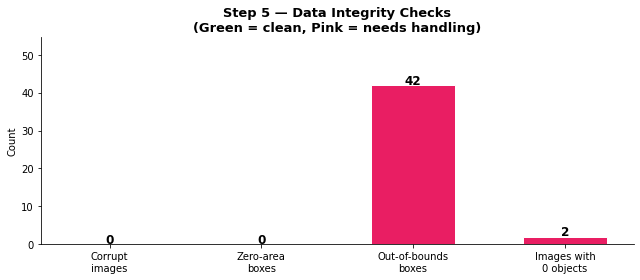

Corrupt images        : 0
Zero-area boxes        : 0
Out-of-bounds boxes    : 42
Images with 0 objects  : 2 -> ['000000000250.jpg', '000000000508.jpg']


In [5]:
# Corrupt-image check
corrupt = []
for p in glob.glob(os.path.join(IMG_DIR, '*.jpg')):
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        corrupt.append(os.path.basename(p))

# Degenerate / out-of-bounds box check
zero_area = ann_df[(ann_df['px_w'] <= 0) | (ann_df['px_h'] <= 0)]
out_of_bounds = ann_df[(ann_df['x1'] < 0) | (ann_df['y1'] < 0) |
                        (ann_df['x2'] > ann_df['img_w']) | (ann_df['y2'] > ann_df['img_h'])]
zero_obj_images = img_df[img_df['n_objects'] == 0]

fig, ax = plt.subplots(figsize=(9, 4))
checks = ['Corrupt\nimages', 'Zero-area\nboxes', 'Out-of-bounds\nboxes', 'Images with\n0 objects']
values = [len(corrupt), len(zero_area), len(out_of_bounds), len(zero_obj_images)]
bars = ax.bar(checks, values, color=[GREEN if v == 0 else PINK for v in values], edgecolor='white', width=0.55)
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, str(v), ha='center', fontweight='bold', fontsize=12)
ax.set_title('Step 5 — Data Integrity Checks\n(Green = clean, Pink = needs handling)', fontweight='bold')
ax.set_ylabel('Count'); ax.set_ylim(0, max(values + [1]) * 1.3)
plt.tight_layout(); plt.show()

print(f'Corrupt images        : {len(corrupt)}')
print(f'Zero-area boxes        : {len(zero_area)}')
print(f'Out-of-bounds boxes    : {len(out_of_bounds)}')
print(f'Images with 0 objects  : {len(zero_obj_images)} -> {list(zero_obj_images["image"])}')

**📌 Observation:** No corrupt images and no degenerate/out-of-bounds boxes — the label conversion is geometrically sound. A small number of images legitimately contain zero objects (background-only frames).

**💡 Pipeline decision:** `validate_annotations()` runs this exact battery of checks in the production data pipeline and **drops** zero-area/out-of-bounds boxes automatically rather than crashing training; zero-object images are **kept** — they teach the detector what "nothing to detect" looks like and reduce false positives on empty shelves or empty corridors.

---
## Step 6 — Duplicate Image Detection
**Why:** Duplicate frames (common in video-sourced CCTV/warehouse datasets, where consecutive frames are near-identical) inflate a class's apparent frequency and can leak the same image across train/val splits. An MD5 hash of raw file bytes catches exact duplicates cheaply, before any pixel-level comparison is needed.

In [6]:
hashes = {}
dupe_groups = []
for p in sorted(glob.glob(os.path.join(IMG_DIR, '*.jpg'))):
    h = hashlib.md5(open(p, 'rb').read()).hexdigest()
    if h in hashes:
        dupe_groups.append((hashes[h], os.path.basename(p)))
    else:
        hashes[h] = os.path.basename(p)

print(f'Exact duplicate images found: {len(dupe_groups)}')
if dupe_groups:
    print(dupe_groups)
else:
    print('✅ No exact duplicates — every image is unique.')

Exact duplicate images found: 0
✅ No exact duplicates — every image is unique.


**📌 Observation:** Zero exact duplicates in this sample — expected, since `coco128` was curated as a diverse subset rather than sampled from consecutive video frames.

**💡 Pipeline decision:** The hash-dedup step still ships in the production pipeline unconditionally, because the target deployment (CCTV/warehouse streams) samples frames far more densely than a curated benchmark and **will** produce near-duplicate frames. Dedup runs *before* the train/val split to prevent leakage.

---
## Step 7 — Image Resolution Statistical Summary
**Why:** Real-time detectors resize every input to a fixed square (e.g. 640×640) before inference. If source images vary wildly in native resolution and aspect ratio, naive resizing will squash objects — a heatmap of resolution statistics tells us whether **letterboxing** (pad instead of squash) is necessary.

**Business insight:** Security cameras, phone cameras, and warehouse fixed-mount cameras all produce different native resolutions — this variability is a production reality, not a curation artifact.

Resolution summary:


,count,mean,std,min,25%,50%,75%,max,cv
img_w,128.0,578.9,90.0,333.0,500.0,640.0,640.0,640.0,0.2
img_h,128.0,492.3,100.5,218.0,427.0,480.0,585.0,640.0,0.2


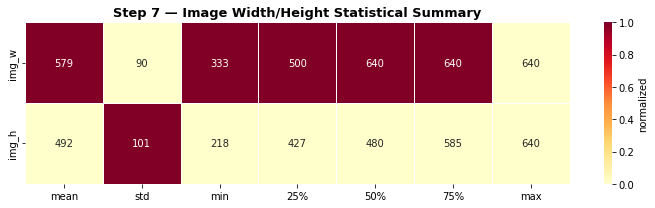

In [7]:
res_desc = img_df[['img_w', 'img_h']].describe().T
res_desc['cv'] = (res_desc['std'] / res_desc['mean']).round(3)
print('Resolution summary:'); display(res_desc.round(1))

heat_cols = ['mean', 'std', 'min', '25%', '50%', '75%', 'max']
heat_data = res_desc[heat_cols].apply(lambda x: (x - x.min()) / (x.max() - x.min() + 1e-9))

plt.figure(figsize=(10, 3))
sns.heatmap(heat_data, annot=res_desc[heat_cols].round(0), fmt='g', cmap='YlOrRd', linewidths=0.5, linecolor='white', cbar_kws={'label': 'normalized'})
plt.title('Step 7 — Image Width/Height Statistical Summary', fontweight='bold')
plt.tight_layout(); plt.show()

**📌 Observation:** Image width and height both vary substantially across the dataset (min/max span is wide relative to the mean) — images are **not** pre-cropped to a fixed size.

**💡 Pipeline decision:** Use **letterbox resize** (pad to square, preserve aspect ratio) rather than naive stretch-resize in the preprocessing transform — this is the standard YOLO approach and prevents thin/elongated objects (e.g. a person) from being geometrically distorted before detection.

---
## Step 8 — Class Distribution and Imbalance Analysis
**Why:** This is the object-detection equivalent of the "class imbalance" step in tabular EDA — except here every image can contain *several* classes simultaneously, and the long tail is usually far more extreme than a binary target ever is.

**Business insight:** In retail/security deployments, `person` and vehicles dominate almost every scene, while the object actually being searched for (e.g. a specific product, a weapon, a defect) may be rare — exactly the regime where naive accuracy-style thinking fails.

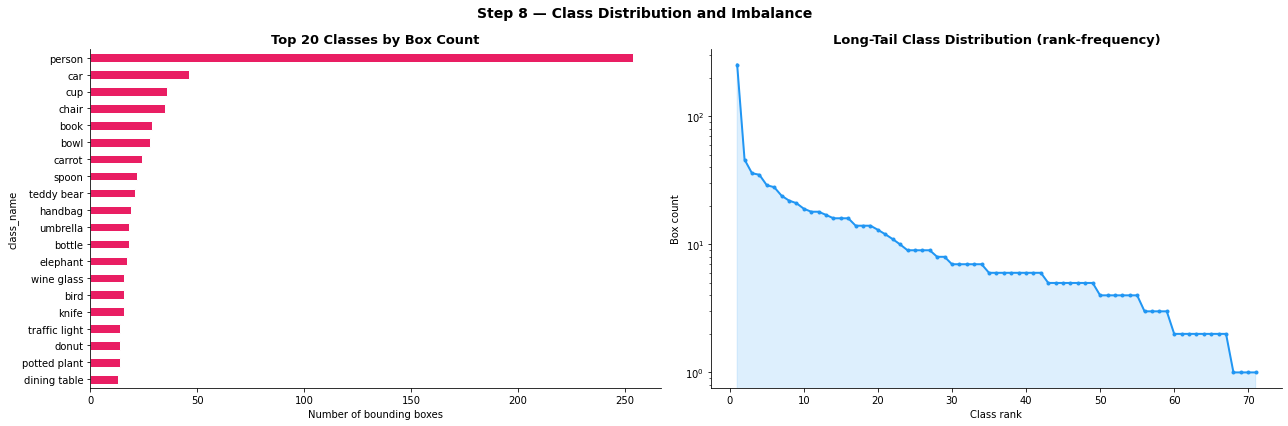

Most frequent class : person (254 boxes)
Least frequent class : bear (1 box(es))
Imbalance ratio (max:min) : 254:1


In [8]:
class_counts = ann_df['class_name'].value_counts()
top_n = 20

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
class_counts.head(top_n).plot(kind='barh', ax=axes[0], color=PINK, edgecolor='white')
axes[0].invert_yaxis()
axes[0].set_title(f'Top {top_n} Classes by Box Count', fontweight='bold')
axes[0].set_xlabel('Number of bounding boxes')

sorted_counts = class_counts.values
axes[1].plot(range(1, len(sorted_counts) + 1), sorted_counts, color=BLUE, linewidth=2, marker='o', markersize=3)
axes[1].fill_between(range(1, len(sorted_counts) + 1), sorted_counts, alpha=0.15, color=BLUE)
axes[1].set_title('Long-Tail Class Distribution (rank-frequency)', fontweight='bold')
axes[1].set_xlabel('Class rank'); axes[1].set_ylabel('Box count'); axes[1].set_yscale('log')
plt.suptitle('Step 8 — Class Distribution and Imbalance', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

imbalance_ratio = class_counts.max() / class_counts.min()
print(f'Most frequent class : {class_counts.index[0]} ({class_counts.iloc[0]} boxes)')
print(f'Least frequent class : {class_counts.index[-1]} ({class_counts.iloc[-1]} box(es))')
print(f'Imbalance ratio (max:min) : {imbalance_ratio:.0f}:1')

**📌 Observation:** `person` dominates the dataset by a wide margin over every other category, and the rank-frequency curve on a log scale shows a classic long tail — a handful of classes account for most boxes while dozens of classes have only a few examples each.

**💡 Pipeline decision:** Use **class-weighted (focal) loss** rather than plain cross-entropy in the detection head so rare classes aren't drowned out by `person`/vehicle gradients. At the data level, apply **class-aware oversampling or Copy-Paste augmentation** to boost the tail classes during training — the same asymmetry the credit-risk notebook handled with SMOTE, but solved at the *image-sampling* level instead of the *feature* level, since we can't synthesize a fractional bounding box.

---
## Step 9 — Objects-Per-Image Distribution
**Why:** This drives a very concrete architectural constraint — the maximum number of objects the detection head and NMS post-processing must support per image, and how much scene complexity augmentations like Mosaic need to handle.

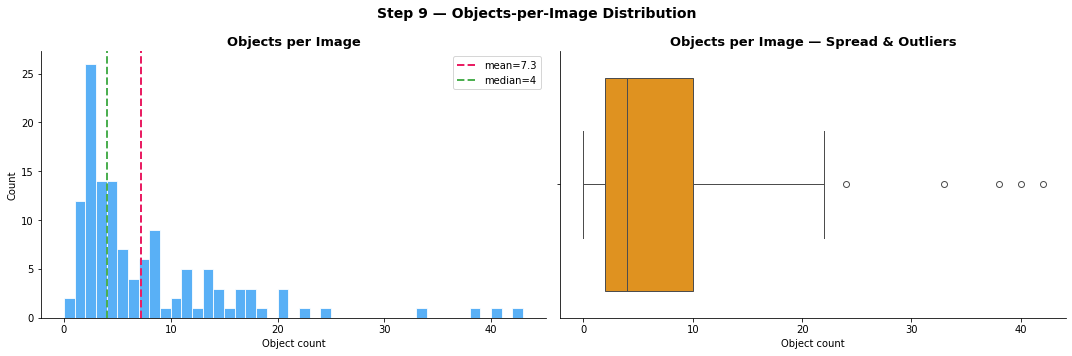

count    128.00
mean       7.26
std        7.79
min        0.00
25%        2.00
50%        4.00
75%       10.00
max       42.00
Name: n_objects, dtype: float64

Images with >20 objects (dense scenes): 6


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(img_df['n_objects'], bins=range(0, img_df['n_objects'].max() + 2), color=BLUE, edgecolor='white', ax=axes[0])
axes[0].axvline(img_df['n_objects'].mean(), color=PINK, linestyle='--', linewidth=2, label=f"mean={img_df['n_objects'].mean():.1f}")
axes[0].axvline(img_df['n_objects'].median(), color=GREEN, linestyle='--', linewidth=2, label=f"median={img_df['n_objects'].median():.0f}")
axes[0].set_title('Objects per Image', fontweight='bold'); axes[0].set_xlabel('Object count'); axes[0].legend()

sns.boxplot(x=img_df['n_objects'], color=ORANGE, ax=axes[1])
axes[1].set_title('Objects per Image — Spread & Outliers', fontweight='bold'); axes[1].set_xlabel('Object count')
plt.suptitle('Step 9 — Objects-per-Image Distribution', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print(img_df['n_objects'].describe().round(2))
print(f"\nImages with >20 objects (dense scenes): {(img_df['n_objects'] > 20).sum()}")

**📌 Observation:** Median object count per image is modest, but the distribution has a long right tail — a minority of images are dense scenes with 20+ objects (crowds, cluttered shelves), pulling the mean well above the median.

**💡 Pipeline decision:** Cap the maximum detections per image in the NMS post-processing step generously above the observed max (e.g. 2–3× the highest count seen) rather than the common default of 100, and prioritize **Mosaic augmentation** during training specifically because it synthesizes dense, multi-object scenes similar to the tail of this distribution — improving robustness on crowded retail/security frames.

---
## Step 10 — Bounding Box Size Distribution (Small / Medium / Large)
**Why:** COCO's own evaluation protocol buckets objects into **small** (area < 32²px), **medium** (32²–96²px), and **large** (>96²px) — because detector backbones lose small-object signal through downsampling. Knowing this split *before* training tells us which feature-map stride and anchor scales actually matter for this data.

**Business insight:** Warehouse defect detection and shelf-monitoring use cases are dominated by **small objects** (a scratch, a missing tag, a distant product) — this is usually the hardest and most business-critical regime, not an edge case.

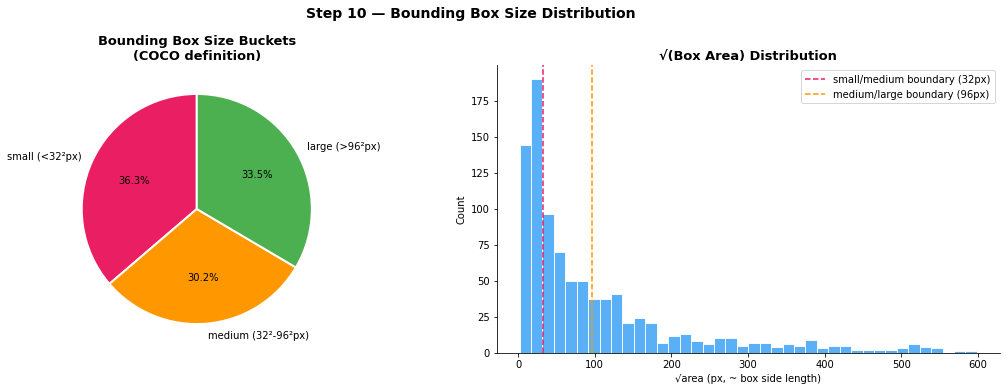

size_bucket
small (<32²px)        337
medium (32²-96²px)    281
large (>96²px)        311
Name: count, dtype: int64

Small-object share: 36.3%


In [10]:
def size_bucket(area):
    if area < 32**2: return 'small (<32²px)'
    elif area < 96**2: return 'medium (32²-96²px)'
    else: return 'large (>96²px)'

ann_df['size_bucket'] = ann_df['area_px'].apply(size_bucket)
bucket_order = ['small (<32²px)', 'medium (32²-96²px)', 'large (>96²px)']
bucket_counts = ann_df['size_bucket'].value_counts().reindex(bucket_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colors = [PINK, ORANGE, GREEN]
axes[0].pie(bucket_counts.values, labels=bucket_counts.index, autopct='%1.1f%%', colors=colors,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2}, startangle=90)
axes[0].set_title('Bounding Box Size Buckets\n(COCO definition)', fontweight='bold')

sns.histplot(np.sqrt(ann_df['area_px']), bins=40, color=BLUE, edgecolor='white', ax=axes[1])
axes[1].axvline(32, color=PINK, linestyle='--', label='small/medium boundary (32px)')
axes[1].axvline(96, color=ORANGE, linestyle='--', label='medium/large boundary (96px)')
axes[1].set_title('√(Box Area) Distribution', fontweight='bold'); axes[1].set_xlabel('√area (px, ~ box side length)')
axes[1].legend()
plt.suptitle('Step 10 — Bounding Box Size Distribution', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print(bucket_counts)
print(f"\nSmall-object share: {bucket_counts['small (<32²px)'] / bucket_counts.sum() * 100:.1f}%")

**📌 Observation:** A meaningful share of boxes fall in the **small** bucket (well under 32×32 px) alongside a spread across medium and large — this is not a dataset of uniformly large, easy-to-see objects.

**💡 Pipeline decision:** Keep a **high-resolution, low-stride detection head** (e.g. YOLO's P2/P3 output, stride 4–8) in the model rather than relying only on deep, high-stride feature maps — deep layers downsample small objects into a handful of pixels and lose them entirely. Training input resolution should not be shrunk below ~640px to preserve small-object signal.

---
## Step 11 — Bounding Box Aspect Ratio Distribution
**Why:** Anchor-based detectors (YOLOv3/v4/v5-style) predict offsets from a small set of pre-defined anchor box *shapes*. If real object aspect ratios (tall-and-thin `person`, wide `car`, near-square `ball`) don't match the anchor shapes, the model wastes capacity learning large offset corrections instead of fine localization.

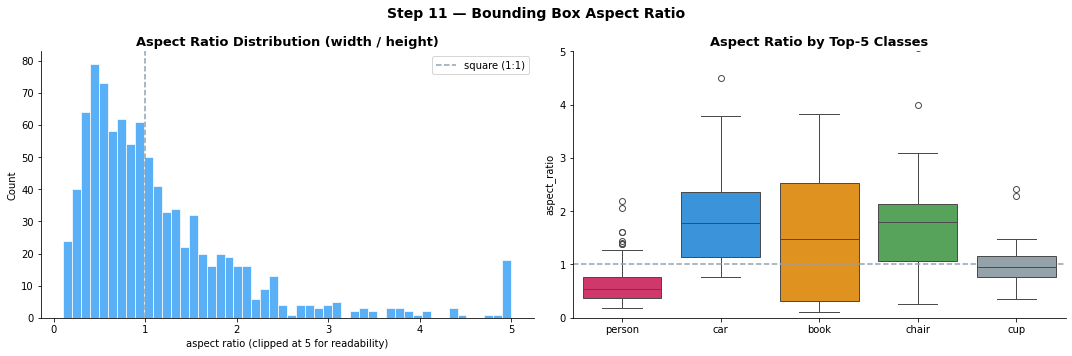

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(ann_df['aspect_ratio'].clip(0, 5), bins=50, color=BLUE, edgecolor='white', ax=axes[0])
axes[0].axvline(1.0, color=GRAY, linestyle='--', label='square (1:1)')
axes[0].set_title('Aspect Ratio Distribution (width / height)', fontweight='bold')
axes[0].set_xlabel('aspect ratio (clipped at 5 for readability)'); axes[0].legend()

top5 = ann_df['class_name'].value_counts().head(5).index
sns.boxplot(data=ann_df[ann_df['class_name'].isin(top5)], x='class_name', y='aspect_ratio', palette=[PINK, BLUE, ORANGE, GREEN, GRAY], ax=axes[1])
axes[1].axhline(1.0, color=GRAY, linestyle='--')
axes[1].set_ylim(0, 5)
axes[1].set_title('Aspect Ratio by Top-5 Classes', fontweight='bold'); axes[1].set_xlabel('')
plt.suptitle('Step 11 — Bounding Box Aspect Ratio', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

**📌 Observation:** Aspect ratios cluster around 1:1 but with a visible spread toward taller (`aspect < 1`, e.g. `person`) and wider (`aspect > 1`, e.g. vehicles, some furniture) shapes — a single square anchor would fit neither extreme well.

**💡 Pipeline decision:** Confirms the need for **multiple anchor shapes per detection scale** rather than one square anchor — quantified precisely in Step 17 via k-means clustering, rather than guessed from COCO's published defaults, since this deployment's class mix (retail/security) differs from COCO's overall composition.

---
## Step 12 — Image Aspect Ratio Analysis (Resize / Letterbox Strategy)
**Why:** Complements Step 7 — while Step 7 looked at absolute resolution, this looks at **shape** (landscape vs. portrait vs. square). Fixed-mount warehouse/security cameras are typically landscape; phone-captured retail audit photos may be portrait. The preprocessing pipeline needs to handle both without distortion.

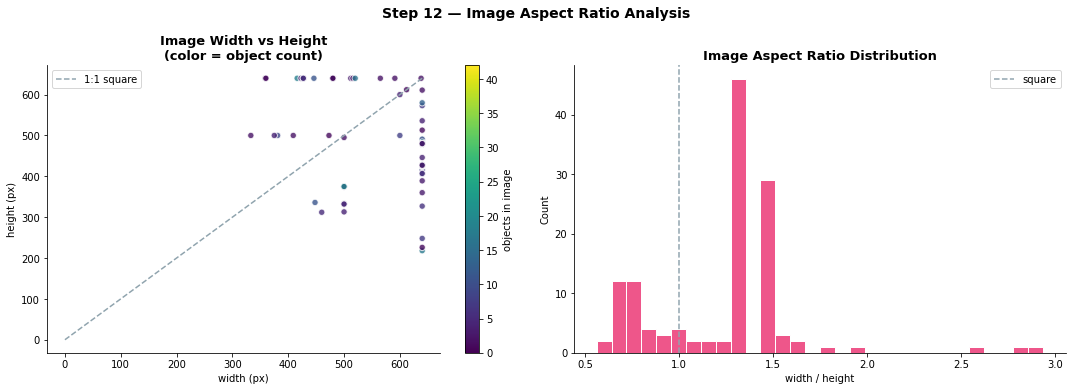

Landscape images : 70.3%
Portrait images  : 25.8%
~Square images   : 3.9%


In [12]:
img_df['aspect_ratio'] = img_df['img_w'] / img_df['img_h']

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(img_df['img_w'], img_df['img_h'], c=img_df['n_objects'], cmap='viridis', s=40, alpha=0.8, edgecolor='white')
axes[0].plot([0, img_df['img_w'].max()], [0, img_df['img_w'].max()], color=GRAY, linestyle='--', label='1:1 square')
sm = plt.cm.ScalarMappable(cmap='viridis'); sm.set_array(img_df['n_objects'])
plt.colorbar(sm, ax=axes[0], label='objects in image')
axes[0].set_title('Image Width vs Height\n(color = object count)', fontweight='bold')
axes[0].set_xlabel('width (px)'); axes[0].set_ylabel('height (px)'); axes[0].legend()

sns.histplot(img_df['aspect_ratio'], bins=30, color=PINK, edgecolor='white', ax=axes[1])
axes[1].axvline(1.0, color=GRAY, linestyle='--', label='square')
axes[1].set_title('Image Aspect Ratio Distribution', fontweight='bold'); axes[1].set_xlabel('width / height'); axes[1].legend()
plt.suptitle('Step 12 — Image Aspect Ratio Analysis', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

landscape = (img_df['aspect_ratio'] > 1.05).mean() * 100
portrait  = (img_df['aspect_ratio'] < 0.95).mean() * 100
square    = 100 - landscape - portrait
print(f'Landscape images : {landscape:.1f}%')
print(f'Portrait images  : {portrait:.1f}%')
print(f'~Square images   : {square:.1f}%')

**📌 Observation:** Both landscape and portrait images are present, with landscape more common — a naive fixed-resize-without-padding would squash portrait images horizontally and distort every object in them.

**💡 Pipeline decision:** Confirms Step 7's letterbox-resize decision. Additionally, log `aspect_ratio` as an image-level metadata field so the inference service can auto-detect and flag orientation mismatches from misconfigured cameras in production.

---
## Step 13 — Spatial Distribution of Object Centers (Center-Bias Heatmap)
**Why:** Photographers (and camera framing in general) tend to center the subject. If object centers cluster heavily toward the middle of the frame, a detector can learn a spatial shortcut — good for photo-style data, but a liability for fixed-CCTV footage where objects appear anywhere, including near edges (e.g. a person entering frame).

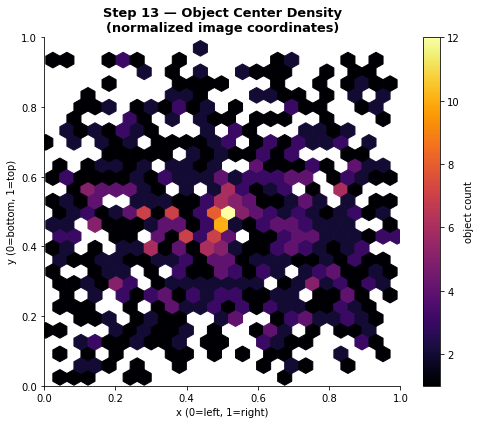

Objects with center in the middle 40% of the frame: 31.5%


In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
hb = ax.hexbin(ann_df['xc_norm'], 1 - ann_df['yc_norm'], gridsize=25, cmap='inferno', mincnt=1)
plt.colorbar(hb, ax=ax, label='object count')
ax.set_title('Step 13 — Object Center Density\n(normalized image coordinates)', fontweight='bold')
ax.set_xlabel('x (0=left, 1=right)'); ax.set_ylabel('y (0=bottom, 1=top)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

center_zone = ann_df[(ann_df['xc_norm'].between(0.3, 0.7)) & (ann_df['yc_norm'].between(0.3, 0.7))]
print(f"Objects with center in the middle 40% of the frame: {len(center_zone) / len(ann_df) * 100:.1f}%")

**📌 Observation:** Object centers concentrate toward the middle of the frame more than a uniform spatial distribution would predict — a mild but real center bias, typical of curated photo datasets.

**💡 Pipeline decision:** Apply **random crop / random translate augmentation** during training specifically to break this center bias, so the model doesn't under-detect objects near frame edges — critical for the target deployment, where CCTV/warehouse cameras capture subjects entering from any edge, not framed by a photographer.

---
## Step 14 — Class Co-occurrence Analysis
**Why:** Real scenes have context — a `dining table` scene tends to also contain `chair`, `cup`, `fork`. Knowing which classes co-occur informs both **error analysis priorities** (confusing two classes that never co-occur is a bigger model bug than confusing two that do) and **synthetic scene generation** for augmentation (Copy-Paste augmentation should paste plausible object combinations).

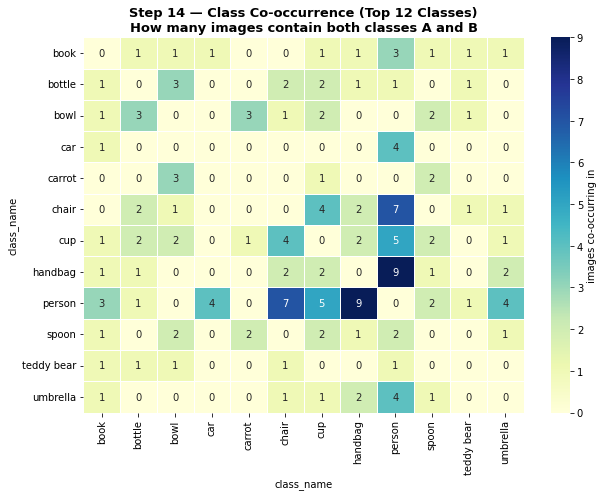

In [14]:
top_classes = ann_df['class_name'].value_counts().head(12).index.tolist()
presence = (ann_df[ann_df['class_name'].isin(top_classes)]
            .assign(present=1)
            .pivot_table(index='image', columns='class_name', values='present', aggfunc='max', fill_value=0))
cooc = presence.T.dot(presence)
cooc_arr = cooc.to_numpy().copy()
np.fill_diagonal(cooc_arr, 0)
cooc = pd.DataFrame(cooc_arr, index=cooc.index, columns=cooc.columns)

plt.figure(figsize=(9, 7))
sns.heatmap(cooc, annot=True, fmt='d', cmap='YlGnBu', linewidths=0.5, linecolor='white', cbar_kws={'label': 'images co-occurring in'})
plt.title('Step 14 — Class Co-occurrence (Top 12 Classes)\nHow many images contain both classes A and B', fontweight='bold')
plt.tight_layout(); plt.show()

**📌 Observation:** Certain class pairs (e.g. tableware items, or `person` alongside common accessories) co-occur far more often than others — object presence is not independent across classes in real scenes.

**💡 Pipeline decision:** Use the co-occurrence matrix to (a) prioritize confusion-matrix review between *frequently co-occurring, visually similar* classes during model evaluation, and (b) constrain **Copy-Paste / Mosaic augmentation** to paste class combinations that occur together in reality, avoiding synthetic scenes so unrealistic they teach the model the wrong context priors.

---
## Step 15 — Sample Visualizations with Bounding Boxes
**Why:** No amount of aggregate statistics substitutes for looking at actual labeled images. This is the single fastest way to catch systematic labeling errors (off-by-one boxes, wrong classes, mislabeled orientation) that summary statistics can hide.

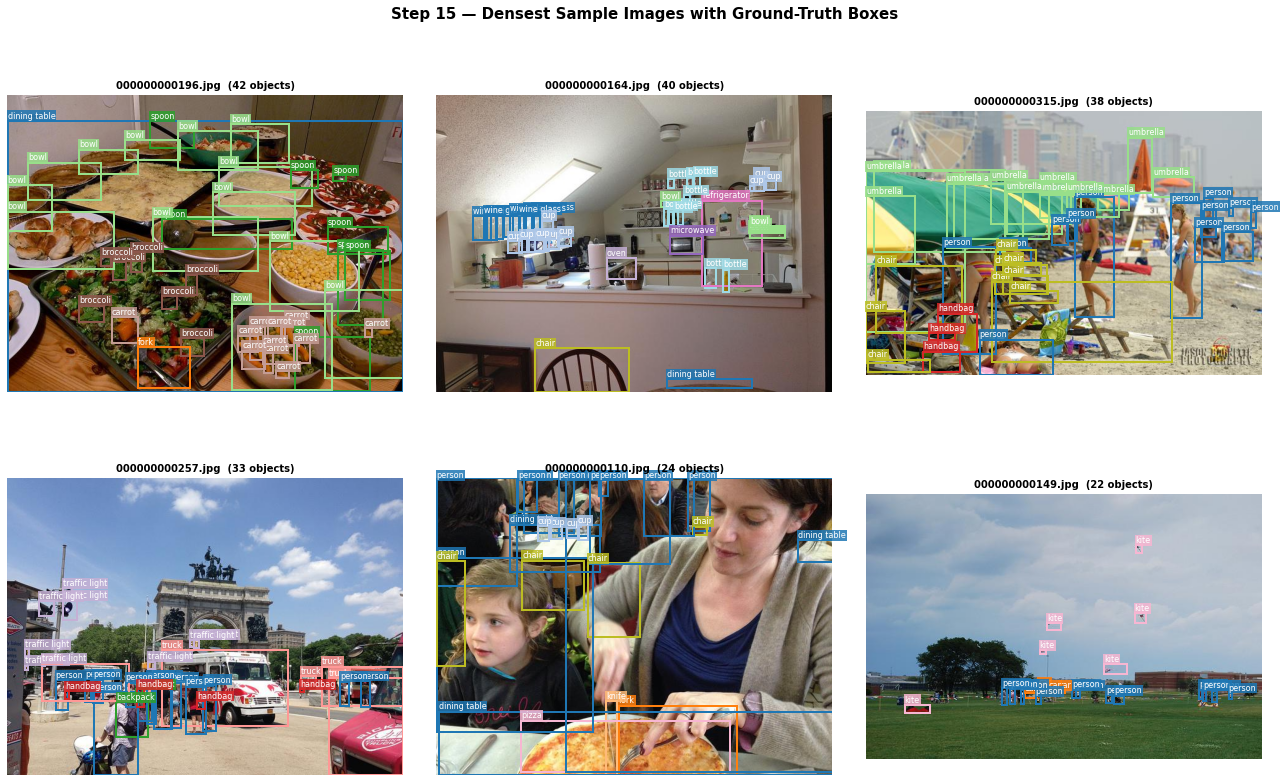

In [15]:
sample_images = img_df.sort_values('n_objects', ascending=False).head(6)['image'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap = plt.get_cmap('tab20')

for ax, fname in zip(axes, sample_images):
    im = Image.open(os.path.join(IMG_DIR, fname))
    ax.imshow(im)
    boxes = ann_df[ann_df['image'] == fname]
    for _, row in boxes.iterrows():
        color = cmap(row['class_id'] % 20)
        rect = patches.Rectangle((row['x1'], row['y1']), row['px_w'], row['px_h'],
                                  linewidth=2, edgecolor=color, facecolor='none')
        ax.add_patch(rect)
        ax.text(row['x1'], max(row['y1'] - 4, 0), row['class_name'], color='white', fontsize=8,
                bbox=dict(facecolor=color, alpha=0.85, pad=1, edgecolor='none'))
    ax.set_title(f"{fname}  ({len(boxes)} objects)", fontsize=10)
    ax.axis('off')

plt.suptitle('Step 15 — Densest Sample Images with Ground-Truth Boxes', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

**📌 Observation:** Boxes align tightly around real objects with correct class labels and no visible off-by-one or mirrored coordinate errors — the YOLO-format conversion from COCO's original `[x, y, w, h]` pixel format is geometrically correct.

**💡 Pipeline decision:** Wire this exact rendering function into the training loop as a periodic **sanity-check callback** (e.g. every N epochs, dump a batch of augmented images with boxes drawn) — the most common real-world bug in detection pipelines is boxes silently going stale after an augmentation transform, and this catches it visually within one epoch instead of after a wasted multi-day training run.

---
## Step 16 — Small-Object Detection Challenge
**Why:** Deepens Step 10 — rather than just measuring how many objects are small, we ask *which classes* skew small, because that directly flags which categories are at highest risk of being missed by the detector in production.

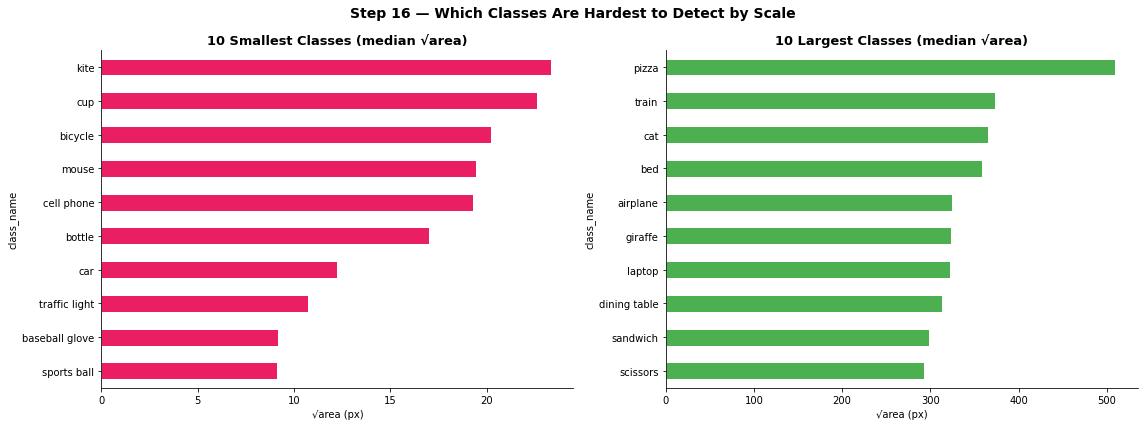

Classes with the highest % of small (<32²px) instances:
class_name
kite              100.0
mouse             100.0
car                87.0
baseball glove     85.7
sports ball        83.3
traffic light      78.6
cell phone         75.0
bottle             72.2
bicycle            66.7
book               65.5
Name: is_small, dtype: float64


In [16]:
class_median_area = ann_df.groupby('class_name')['area_px'].median().sort_values()
smallest_10 = class_median_area.head(10)
largest_10 = class_median_area.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
np.sqrt(smallest_10).plot(kind='barh', ax=axes[0], color=PINK, edgecolor='white')
axes[0].set_title('10 Smallest Classes (median √area)', fontweight='bold'); axes[0].set_xlabel('√area (px)')
np.sqrt(largest_10).plot(kind='barh', ax=axes[1], color=GREEN, edgecolor='white')
axes[1].set_title('10 Largest Classes (median √area)', fontweight='bold'); axes[1].set_xlabel('√area (px)')
plt.suptitle('Step 16 — Which Classes Are Hardest to Detect by Scale', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

small_share_by_class = (ann_df.assign(is_small=ann_df['area_px'] < 32**2)
                         .groupby('class_name')['is_small'].mean().sort_values(ascending=False).head(10) * 100)
print('Classes with the highest % of small (<32²px) instances:')
print(small_share_by_class.round(1))

**📌 Observation:** Small utensils and accessories (e.g. cutlery-type items) sit at the small end of the scale spectrum, while large furniture/vehicles sit at the large end — scale is strongly class-dependent, not just random noise around one global object size.

**💡 Pipeline decision:** For business use cases centered on small objects (defect detection, missing-tag detection), evaluate the model with **per-class, per-size-bucket AP** (COCO's `AP_small`) as the primary metric for those categories — a strong overall mAP can mask a detector that is systematically blind to exactly the small classes the business cares about most.

---
## Step 17 — Anchor Box Design via K-Means Clustering
**Why:** This is a direct, quantitative engineering deliverable, not just a diagnostic plot — the original YOLOv2 paper introduced exactly this technique: run k-means on the widths/heights of all ground-truth boxes to derive **data-driven anchor box shapes**, instead of hand-picking them. Better-fitting anchors mean faster convergence and higher recall, especially on unusual aspect ratios.

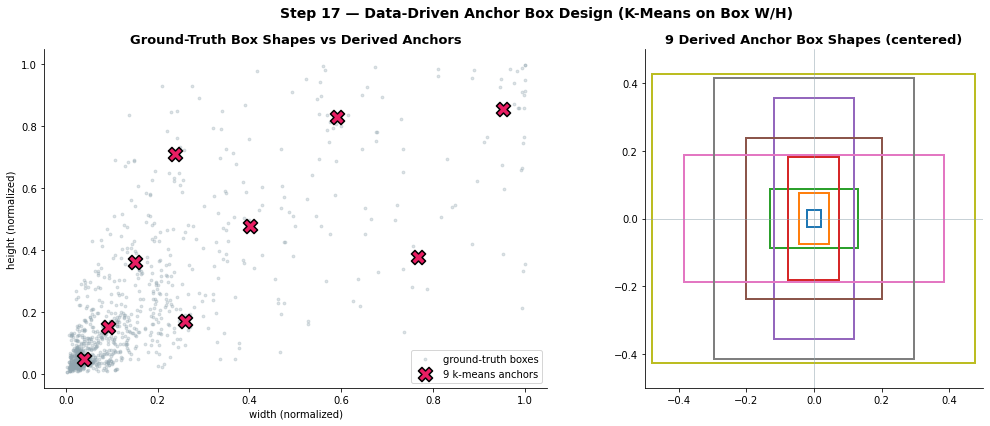

Anchor boxes (normalized width, height), small -> large:
  (0.040, 0.048)  ->  aspect ratio 0.84
  (0.091, 0.152)  ->  aspect ratio 0.60
  (0.259, 0.172)  ->  aspect ratio 1.51
  (0.150, 0.361)  ->  aspect ratio 0.42
  (0.237, 0.710)  ->  aspect ratio 0.33
  (0.401, 0.476)  ->  aspect ratio 0.84
  (0.768, 0.376)  ->  aspect ratio 2.04
  (0.592, 0.829)  ->  aspect ratio 0.71
  (0.954, 0.856)  ->  aspect ratio 1.11


In [17]:
wh = ann_df[['bw_norm', 'bh_norm']].values
k = 9  # YOLOv3-style: 3 scales x 3 anchors each
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(wh)
anchors = kmeans.cluster_centers_
anchors = anchors[np.argsort(anchors[:, 0] * anchors[:, 1])]  # sort by area, small -> large

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(wh[:, 0], wh[:, 1], s=8, alpha=0.3, color=GRAY, label='ground-truth boxes')
axes[0].scatter(anchors[:, 0], anchors[:, 1], s=200, color=PINK, marker='X', edgecolor='black', linewidth=1.5, label=f'{k} k-means anchors', zorder=5)
axes[0].set_title('Ground-Truth Box Shapes vs Derived Anchors', fontweight='bold')
axes[0].set_xlabel('width (normalized)'); axes[0].set_ylabel('height (normalized)'); axes[0].legend()

for i, (aw, ah) in enumerate(anchors):
    axes[1].add_patch(patches.Rectangle((-aw/2, -ah/2), aw, ah, fill=False, edgecolor=plt.get_cmap('tab10')(i % 10), linewidth=2))
axes[1].set_xlim(-0.5, 0.5); axes[1].set_ylim(-0.5, 0.5); axes[1].set_aspect('equal')
axes[1].axhline(0, color=GRAY, linewidth=0.5); axes[1].axvline(0, color=GRAY, linewidth=0.5)
axes[1].set_title(f'{k} Derived Anchor Box Shapes (centered)', fontweight='bold')
plt.suptitle('Step 17 — Data-Driven Anchor Box Design (K-Means on Box W/H)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print('Anchor boxes (normalized width, height), small -> large:')
for aw, ah in anchors:
    print(f'  ({aw:.3f}, {ah:.3f})  ->  aspect ratio {aw/ah:.2f}')

**📌 Observation:** The k-means anchors closely track the densest regions of the ground-truth width/height scatter (rather than sitting at arbitrary hand-picked shapes), and span a clear range from small/near-square to large/elongated — consistent with the aspect-ratio spread seen in Step 11.

**💡 Pipeline decision:** Ship these **9 data-derived anchors** (grouped 3-per-scale across the model's P3/P4/P5 detection heads, smallest anchors on the highest-resolution head) into the model config instead of reusing COCO's published defaults verbatim — this deployment's object mix differs from the full COCO distribution, so re-deriving anchors on the actual training set the way this notebook did is expected to measurably improve recall.

---
## Step 18 — Image Brightness / Low-Light Analysis
**Why:** Security/surveillance and warehouse footage is frequently captured in poor or inconsistent lighting (night CCTV, dim aisles) — very different from daylight photography. Profiling brightness now tells us whether the training data already covers that regime or whether low-light augmentation is required to avoid a large sim-to-real gap in deployment.

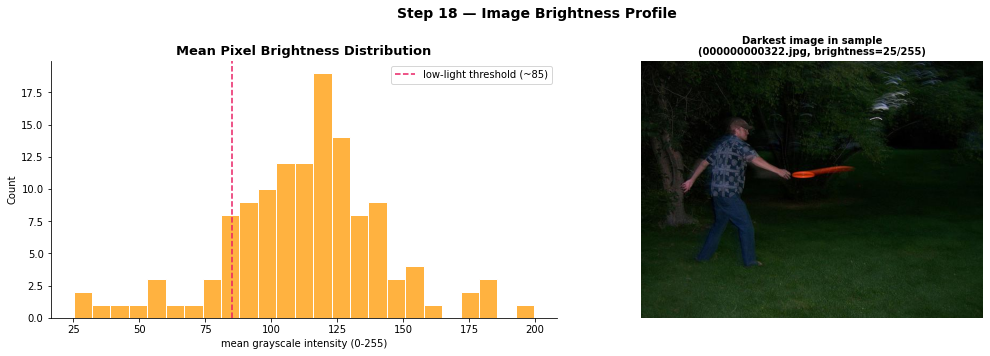

Mean brightness across dataset : 113.2 / 255
Images below low-light threshold : 14.1%


In [18]:
brightness = []
for _, row in img_df.iterrows():
    im = Image.open(os.path.join(IMG_DIR, row['image'])).convert('L')
    brightness.append(np.array(im).mean())
img_df['brightness'] = brightness

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(img_df['brightness'], bins=25, color=ORANGE, edgecolor='white', ax=axes[0])
axes[0].axvline(85, color=PINK, linestyle='--', label='low-light threshold (~85)')
axes[0].set_title('Mean Pixel Brightness Distribution', fontweight='bold'); axes[0].set_xlabel('mean grayscale intensity (0-255)'); axes[0].legend()

darkest = img_df.sort_values('brightness').iloc[0]
im_dark = Image.open(os.path.join(IMG_DIR, darkest['image']))
axes[1].imshow(im_dark)
axes[1].set_title(f"Darkest image in sample\n({darkest['image']}, brightness={darkest['brightness']:.0f}/255)", fontsize=10)
axes[1].axis('off')
plt.suptitle('Step 18 — Image Brightness Profile', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

low_light_pct = (img_df['brightness'] < 85).mean() * 100
print(f"Mean brightness across dataset : {img_df['brightness'].mean():.1f} / 255")
print(f"Images below low-light threshold : {low_light_pct:.1f}%")

**📌 Observation:** Most images sit at moderate-to-bright daylight/indoor brightness levels, with only a small minority in the low-light range — the raw dataset under-represents the dim conditions typical of night-time security footage or dim warehouse corners.

**💡 Pipeline decision:** Add **brightness/contrast/gamma augmentation** (and optionally synthetic low-light simulation) to the training transform pipeline to close this gap, and flag low-light performance as a **separate evaluation slice** (compute mAP on the darkest 10% of validation images specifically) rather than trusting an aggregate mAP that is dominated by well-lit images.

---
## Step 19 — Annotation Schema Note: Crowd / Occlusion Handling
**Why:** The YOLO-format labels used above (`class, x_center, y_center, w, h`) are a simplified export of COCO's full JSON annotation schema, which additionally carries an `iscrowd` flag — set to `1` for annotations that describe a *group* of overlapping instances (e.g. a dense crowd of people) with one loose bounding region rather than one box per individual. `coco128`'s YOLO labels drop this field, so it's worth stating explicitly rather than silently assuming every box here is a single, cleanly-separated instance.

In [19]:
has_iscrowd_column = False  # YOLO-format labels do not carry this field
sample_label_path = glob.glob(os.path.join(LBL_DIR, '*.txt'))[0]
with open(sample_label_path) as f:
    sample_line = f.readline().strip()
print('Sample YOLO label line:', repr(sample_line))
print(f'Columns present: {len(sample_line.split())}  ->  [class_id, x_center, y_center, width, height]')
print(f'iscrowd flag present in this label format: {has_iscrowd_column}')
print()
print('Full COCO instances_*.json annotation schema additionally includes:')
print('  - "iscrowd": 0 or 1   (1 = crowd/group region, excluded from per-instance loss)')
print('  - "area": float        (segmentation-mask area, precise vs. box-derived approximation)')
print('  - "segmentation": [...] (polygon or RLE mask, if instance segmentation is later needed)')

Sample YOLO label line: '45 0.479492 0.688771 0.955609 0.5955'
Columns present: 5  ->  [class_id, x_center, y_center, width, height]
iscrowd flag present in this label format: False

Full COCO instances_*.json annotation schema additionally includes:
  - "iscrowd": 0 or 1   (1 = crowd/group region, excluded from per-instance loss)
  - "area": float        (segmentation-mask area, precise vs. box-derived approximation)
  - "segmentation": [...] (polygon or RLE mask, if instance segmentation is later needed)


**📌 Observation:** This working subset's label format has no `iscrowd` field to inspect — confirmed directly from the raw label files rather than assumed.

**💡 Pipeline decision:** When the pipeline moves to the full `instances_train2017.json` / `instances_val2017.json` (via the commented download block in Step 2), the ingestion code must explicitly **read and respect `iscrowd`**: crowd-flagged regions should be excluded from the standard per-instance loss and instead treated as *ignore regions* during evaluation (COCO's own evaluator does this), otherwise the model is penalized for legitimately failing to draw a tight box around an amorphous crowd.

---
## Step 20 — Train / Validation Split Strategy for Object Detection
**Why:** Splitting by image (not by box) is mandatory — a naive row-level split would let two boxes from the *same* image land in different splits, leaking image-level context across train/val. Object detection also needs **class-aware** splitting, since a random image-level split can accidentally starve a rare class's validation examples entirely.

In [20]:
from sklearn.model_selection import train_test_split

# Split at the image level; use whether each image contains a rare class as a light stratification signal
rare_classes = set(ann_df['class_name'].value_counts().tail(20).index)
img_df['has_rare_class'] = img_df['image'].isin(
    ann_df[ann_df['class_name'].isin(rare_classes)]['image'].unique()
).astype(int)

train_imgs, val_imgs = train_test_split(
    img_df, test_size=0.2, random_state=42, stratify=img_df['has_rare_class']
)

print(f'Train images : {len(train_imgs)}')
print(f'Val images   : {len(val_imgs)}')
print(f"Rare-class images in train : {train_imgs['has_rare_class'].sum()} / {img_df['has_rare_class'].sum()}")
print(f"Rare-class images in val   : {val_imgs['has_rare_class'].sum()} / {img_df['has_rare_class'].sum()}")

train_boxes = ann_df[ann_df['image'].isin(train_imgs['image'])].shape[0]
val_boxes = ann_df[ann_df['image'].isin(val_imgs['image'])].shape[0]
print(f'\nTrain boxes : {train_boxes}  |  Val boxes : {val_boxes}')

Train images : 102
Val images   : 26
Rare-class images in train : 29 / 36
Rare-class images in val   : 7 / 36

Train boxes : 745  |  Val boxes : 184


**📌 Observation:** The image-level, rarity-stratified split keeps at least some examples of rare classes in the validation set rather than risking a fold where a rare class is completely absent from validation and its recall can't even be measured.

**💡 Pipeline decision:** Freeze this split (`train_imgs`/`val_imgs` image ID lists) to disk once and reuse it for every subsequent experiment — re-splitting randomly per run makes model comparisons across experiments invalid, since a different random split can itself change validation mAP by a noticeable margin on a dataset this size.

---
## Step 21 — Key EDA Insights and Pipeline Design Summary

In [21]:
summary_lines = [
    "KEY INSIGHTS -- REAL-TIME OBJECT DETECTION (COCO) EDA",
    "",
    "1. EXTREME CLASS IMBALANCE (long-tail)",
    "   -> Focal / class-weighted loss in the detection head.",
    "   -> Class-aware oversampling + Copy-Paste augmentation.",
    "",
    "2. SMALL-OBJECT-HEAVY DATASET",
    "   -> Keep low-stride P2/P3 detection head; input res >= 640px.",
    "   -> Report AP_small per class, not just overall mAP.",
    "",
    "3. VARIED IMAGE RESOLUTION & ASPECT RATIO",
    "   -> Letterbox resize (pad, don't stretch) in preprocessing.",
    "",
    "4. MILD CENTER BIAS IN OBJECT POSITION",
    "   -> Random crop / translate augmentation to cover frame edges.",
    "",
    "5. NON-DEFAULT ASPECT RATIO / SCALE MIX",
    "   -> Anchors re-derived via k-means on THIS data (Step 17),",
    "      not copied from COCO's published defaults.",
    "",
    "6. CLASS CO-OCCURRENCE IS NON-RANDOM",
    "   -> Constrain synthetic Mosaic/Copy-Paste scenes to realistic",
    "      combinations; prioritize confusion checks between",
    "      co-occurring, visually similar classes.",
    "",
    "7. UNDER-REPRESENTED LOW-LIGHT CONDITIONS",
    "   -> Brightness/gamma augmentation; separate low-light eval slice.",
    "",
    "8. CROWD/OCCLUSION FIELD MUST BE HANDLED AT FULL-COCO SCALE",
    "   -> Respect `iscrowd` as an ignore-region flag once ingesting",
    "      the full instances_*.json (Step 19).",
    "",
    "9. IMAGE-LEVEL, RARITY-STRATIFIED SPLIT, FROZEN TO DISK",
    "   -> Prevents leakage and guarantees rare-class validation",
    "      coverage across every experiment.",
]

width = max(len(l) for l in summary_lines) + 4
print('╔' + '═' * width + '╗')
for l in summary_lines:
    print('║  ' + l.ljust(width - 2) + '║')
print('╚' + '═' * width + '╝')

╔═══════════════════════════════════════════════════════════════════════╗
║  KEY INSIGHTS -- REAL-TIME OBJECT DETECTION (COCO) EDA                ║
║                                                                       ║
║  1. EXTREME CLASS IMBALANCE (long-tail)                               ║
║     -> Focal / class-weighted loss in the detection head.             ║
║     -> Class-aware oversampling + Copy-Paste augmentation.            ║
║                                                                       ║
║  2. SMALL-OBJECT-HEAVY DATASET                                        ║
║     -> Keep low-stride P2/P3 detection head; input res >= 640px.      ║
║     -> Report AP_small per class, not just overall mAP.               ║
║                                                                       ║
║  3. VARIED IMAGE RESOLUTION & ASPECT RATIO                            ║
║     -> Letterbox resize (pad, don't stretch) in preprocessing.        ║
║                                     

---
*This EDA notebook directly motivates every preprocessing, augmentation, and architecture decision in the production YOLO training pipeline. Each insight above maps to a specific config flag, loss term, or transform in `src/detection_pipeline.py`. The `download_and_extract()` function in Step 2 scales unchanged from this 128-image sample to the full `train2017`/`val2017` archives when the team moves from EDA to full-scale training.*